# 09 - SD3 counterfactual SAE causal mediation v2



## 0. Imports, project root, and storage


In [2]:
from pathlib import Path
from collections import defaultdict
import gc
import hashlib
import itertools
import json
import math
import os
import random
import re
import sys
import warnings

import numpy as np
import pandas as pd
from IPython.display import display


def _looks_like_repo(path: Path) -> bool:
    return (path / "src" / "diffusion_attention_analysis_v2").exists() and (path / "configs").exists()


def _find_project_root() -> Path:
    candidates=[]
    if os.environ.get("PROJECT_ROOT"):
        candidates.append(Path(os.environ["PROJECT_ROOT"]))
    cwd=Path.cwd().resolve()
    candidates.extend([cwd,*cwd.parents])
    candidates.extend([
        Path("/home/jupyter/project/diffusion_attention_analysis_2"),
        Path("/home/jupyter/datasphere/project/diffusion_attention_analysis_2"),
    ])
    for p in candidates:
        p=p.expanduser().resolve()
        if _looks_like_repo(p):
            return p
    raise FileNotFoundError("PROJECT_ROOT manually.")

PROJECT_ROOT=_find_project_root()
os.chdir(PROJECT_ROOT)
SRC=PROJECT_ROOT/"src"
if str(SRC) not in sys.path:
    sys.path.insert(0,str(SRC))
os.environ["PYTHONPATH"]=str(SRC)+os.pathsep+os.environ.get("PYTHONPATH","")

from diffusion_attention_analysis_v2.activations import (
    extract_first_tensor, flatten_feature_map, remove_hooks,
    replace_first_tensor, unflatten_feature_map,
)
from diffusion_attention_analysis_v2.config import deep_get, load_config, resolve_path
from diffusion_attention_analysis_v2.io_utils import module_to_filename, safe_name
from diffusion_attention_analysis_v2.pipelines import generation_kwargs, get_denoiser_module, load_pipeline
from diffusion_attention_analysis_v2.sae import load_sae_checkpoint
from diffusion_attention_analysis_v2.sd3_notebook_utils import feature_specificity, prepare_datashere_storage

RUN_TAG="sd3_medium_sae_circuit_150"
CONTAINER_NAME="container4"
CONFIG_PATH=PROJECT_ROOT/"configs/06_causal_analysis/sd3_medium_counterfactual_sae_mediation_v2.yaml"

storage_info=prepare_datashere_storage(
    project_root=PROJECT_ROOT,
    run_tag=RUN_TAG,
    container_name=CONTAINER_NAME,
    require_container=True,
    min_free_gb=35.0,
)
display(pd.DataFrame([storage_info]))

cfg=load_config(CONFIG_PATH)
OUT_DIR=resolve_path(cfg,"data.output_dir",required=True)
PROMPTS_PATH=resolve_path(cfg,"data.prompts_path",required=True)
OUT_DIR.mkdir(parents=True,exist_ok=True)
for p in ["clean_cache","phase_a","phase_b","figures","galleries"]:
    (OUT_DIR/p).mkdir(parents=True,exist_ok=True)

DEVICE=str(deep_get(cfg,"model.device","cuda"))
TARGET_LABELS=[str(x).lower() for x in deep_get(cfg,"design.target_labels",[])]
RUN_SITES=[s for s,scfg in cfg["sites"].items() if bool(scfg.get("enabled",False))]
RUN_CONFIRMATORY=bool(deep_get(cfg,"design.run_confirmatory",False))

RUN_CLEAN_CAPTURE=bool(deep_get(cfg,"runtime.run_clean_capture",True))
RUN_FEATURE_DISCOVERY=bool(deep_get(cfg,"runtime.run_feature_discovery",True))
RUN_PHASE_A=bool(deep_get(cfg,"runtime.run_phase_a",True))
RUN_PHASE_A_SCORING=bool(deep_get(cfg,"runtime.run_phase_a_scoring",True))
RUN_PHASE_B_IF_GATE=bool(deep_get(cfg,"runtime.run_phase_b_if_gate_passes",True))
RUN_FINAL_SCORING=bool(deep_get(cfg,"runtime.run_final_scoring",True))
FORCE_CLEAN=bool(deep_get(cfg,"runtime.force_rerun_clean",False))
FORCE_A=bool(deep_get(cfg,"runtime.force_rerun_phase_a",False))
FORCE_B=bool(deep_get(cfg,"runtime.force_rerun_phase_b",False))

print("PROJECT_ROOT:",PROJECT_ROOT)
print("CONFIG:",CONFIG_PATH)
print("OUTPUT:",OUT_DIR)
print("SITES:",RUN_SITES)
print("RUN_CONFIRMATORY:",RUN_CONFIRMATORY)


,project_root,container,run_tag,output_run_root,annotation_run_root,tmp_root,pip_cache_dir,hf_home,free_gb,min_free_gb,free_space_ok
0,/home/jupyter/project/diffusion_attention_anal...,/home/jupyter/filestore/container4,sd3_medium_sae_circuit_150,/home/jupyter/filestore/container4/diffusion_a...,/home/jupyter/filestore/container4/diffusion_a...,/home/jupyter/filestore/container4/tmp/sd3_med...,/home/jupyter/filestore/container4/pip_cache,/home/jupyter/filestore/container4/hf_home,90.836018,35.0,True


PROJECT_ROOT: /home/jupyter/project/diffusion_attention_analysis_2
CONFIG: /home/jupyter/project/diffusion_attention_analysis_2/configs/06_causal_analysis/sd3_medium_counterfactual_sae_mediation_v2.yaml
OUTPUT: /home/jupyter/project/diffusion_attention_analysis_2/outputs/sd3_medium_sae_circuit_150/06_causal_mediation_v2
SITES: ['early', 'mid']
RUN_CONFIRMATORY: False


In [22]:
RUN_CONFIRMATORY = True
RUN_SITES = ["mid"]

## 1. Deterministic source/destination split with no source-prompt reuse


In [23]:
def read_jsonl(path: Path):
    return [json.loads(x) for x in path.read_text(encoding="utf-8").splitlines() if x.strip()]


def labels_in_row(row):
    return [str(e.get("label",e.get("token",""))).lower().strip() for e in (row.get("entities",[]) or []) if str(e.get("label",e.get("token",""))).strip()]


def replace_token(text,old,new):
    pattern=re.compile(rf"\b{re.escape(old)}\b",flags=re.IGNORECASE)
    out,n=pattern.subn(new,str(text),count=1)
    if n!=1:
        raise ValueError(f"Could not replace exactly one {old!r} in {text!r}")
    return out


def stable_rank(seed,label,row_id):
    raw=f"{seed}|{label}|{row_id}".encode("utf-8")
    return int(hashlib.sha256(raw).hexdigest()[:16],16)


def build_split(rows):
    n_disc=int(deep_get(cfg,"design.discovery_prompts_per_label",3))
    n_eval=int(deep_get(cfg,"design.evaluation_prompts_per_label",2))
    n_conf=int(deep_get(cfg,"design.confirmatory_prompts_per_label",2))
    total=n_disc+n_eval+n_conf
    split_seed=int(deep_get(cfg,"design.split_seed",2601))
    replacement_pool=[str(x).lower() for x in deep_get(cfg,"design.replacement_pool",[])]
    used=set(); pairs=[]
    for label in TARGET_LABELS:
        candidates=[]
        for row in rows:
            if row["id"] in used or label not in labels_in_row(row):
                continue
            priority=0 if str(row.get("target_word","")).lower()==label else 1
            candidates.append((priority,stable_rank(split_seed,label,row["id"]),row))
        candidates.sort(key=lambda x:(x[0],x[1]))
        chosen=[x[2] for x in candidates[:total]]
        if len(chosen)<total:
            raise RuntimeError(f"Need {total} globally unique prompts for {label}, found {len(chosen)}")
        used.update(r["id"] for r in chosen)
        split_names=["discovery"]*n_disc+["evaluation"]*n_eval+["confirmatory"]*n_conf
        for rank,(source,split_name) in enumerate(zip(chosen,split_names)):
            occupied=set(labels_in_row(source))
            repl_candidates=[x for x in replacement_pool if x not in occupied and x!=label]
            if not repl_candidates:
                raise RuntimeError(f"No replacement for {label}: {source['id']}")
            repl_idx=stable_rank(split_seed+17,label,source["id"])%len(repl_candidates)
            replacement=repl_candidates[repl_idx]
            dst_prompt=replace_token(source["prompt"],label,replacement)
            dst_entities=[]
            for ent in source.get("entities",[]) or []:
                item=dict(ent)
                if str(item.get("label",item.get("token",""))).lower()==label:
                    item["label"]=replacement; item["token"]=replacement
                dst_entities.append(item)
            pair_id=f"{safe_name(str(source['id']))}__{label}_to_{replacement}"
            pairs.append({
                "pair_id":pair_id,"split":split_name,"label":label,"replacement_label":replacement,
                "source_id":str(source["id"]),"source_prompt":str(source["prompt"]),"destination_prompt":dst_prompt,
                "source_entities":source.get("entities",[]),"destination_entities":dst_entities,
                "source_was_target_word":str(source.get("target_word","")).lower()==label,
                "rank_within_label":rank,
            })
    return pairs

all_prompt_rows=read_jsonl(PROMPTS_PATH)
pairs=build_split(all_prompt_rows)
pairs_df=pd.DataFrame(pairs)
pairs_df.to_csv(OUT_DIR/"split_manifest.csv",index=False)
assert pairs_df["source_id"].is_unique, "source-prompt leakage across labels"

discovery_pairs=[p for p in pairs if p["split"]=="discovery"]
evaluation_pairs=[p for p in pairs if p["split"]=="evaluation"]
confirmatory_pairs=[p for p in pairs if p["split"]=="confirmatory"]
active_test_pairs=confirmatory_pairs if RUN_CONFIRMATORY else evaluation_pairs

print("discovery/evaluation/confirmatory:",len(discovery_pairs),len(evaluation_pairs),len(confirmatory_pairs))
display(pairs_df.groupby(["split","label"]).size().rename("n").reset_index())
display(pairs_df[["split","label","replacement_label","source_id","source_was_target_word","source_prompt","destination_prompt"]])


discovery/evaluation/confirmatory: 18 12 12


,split,label,n
0,confirmatory,bicycle,2
1,confirmatory,book,2
2,confirmatory,car,2
3,confirmatory,cat,2
4,confirmatory,dog,2
5,confirmatory,person,2
6,discovery,bicycle,3
7,discovery,book,3
8,discovery,car,3
9,discovery,cat,3


,split,label,replacement_label,source_id,source_was_target_word,source_prompt,destination_prompt
0,discovery,dog,lamp,sd3_circuit_030_dog_table,True,realistic photo of a dog next to a table on a ...,realistic photo of a lamp next to a table on a...
1,discovery,dog,chair,sd3_circuit_090_dog_table,True,realistic photo of a dog next to a table near ...,realistic photo of a chair next to a table nea...
2,discovery,dog,chair,sd3_circuit_120_dog_table,True,realistic photo of a dog next to a table on a ...,realistic photo of a chair next to a table on ...
3,evaluation,dog,flower,sd3_circuit_000_dog_table,True,realistic photo of a dog next to a table insid...,realistic photo of a flower next to a table in...
4,evaluation,dog,flower,sd3_circuit_060_dog_table,True,realistic photo of a dog next to a table in a ...,realistic photo of a flower next to a table in...
5,confirmatory,dog,bed,sd3_circuit_007_tree_dog,False,studio photo of a tree near a dog on a city st...,studio photo of a tree near a bed on a city st...
6,confirmatory,dog,bed,sd3_circuit_037_tree_dog,False,studio photo of a tree near a dog in a small park,studio photo of a tree near a bed in a small park
7,discovery,cat,chair,sd3_circuit_091_cat_umbrella,True,documentary photo of a cat near a umbrella nea...,documentary photo of a chair near a umbrella n...
8,discovery,cat,lamp,sd3_circuit_031_cat_umbrella,True,documentary photo of a cat near a umbrella on ...,documentary photo of a lamp near a umbrella on...
9,discovery,cat,apple,sd3_circuit_001_cat_umbrella,True,documentary photo of a cat near a umbrella ins...,documentary photo of a apple near a umbrella i...


## 2. Site definitions and compute budget


In [24]:
site_rows=[]
for site in RUN_SITES:
    scfg=cfg["sites"][site]
    site_rows.append({
        "site":site,"module":scfg["module"],"anchor":int(scfg["anchor_step"]),
        "window":list(map(int,scfg["window_steps"])),
        "sae":str(resolve_path(cfg,f"sites.{site}.sae_checkpoint",required=True)),
    })
display(pd.DataFrame(site_rows))

n_clean_pairs=len(discovery_pairs)+len(active_test_pairs)
phase_a_arms=[str(x) for x in deep_get(cfg,"patching.phase_a_arms",[])]
phase_b_arms=[str(x) for x in deep_get(cfg,"patching.phase_b_arms",[])]
budget=pd.DataFrame([
    {"component":"clean source+destination capture","runs":2*n_clean_pairs},
    {"component":"phase A interventions","runs":len(active_test_pairs)*len(RUN_SITES)*len(phase_a_arms)},
    {"component":"maximum phase B if every site passes","runs":len(active_test_pairs)*len(RUN_SITES)*len(phase_b_arms)},
])
display(budget)


,site,module,anchor,window,sae
0,mid,transformer_blocks.11,13,"[11, 12, 13, 14, 15]",/home/jupyter/project/diffusion_attention_anal...


,component,runs
0,clean source+destination capture,60
1,phase A interventions,84
2,maximum phase B if every site passes,72


## 3. Clean trajectory capture


In [25]:
import torch
from PIL import Image


def run_pipe(pipe,prompt,seed,*,denoiser,hook_handles_fn=None):
    device=str(deep_get(cfg,"model.device","cuda"))
    gen=torch.Generator(device=device if device=="cuda" and torch.cuda.is_available() else "cpu").manual_seed(int(seed))
    current={"step":-1}; calls={"idx":-1}
    def root_pre_hook(module,inputs):
        calls["idx"]+=1; current["step"]=int(calls["idx"])
    def step_getter(): return int(current["step"])
    root=denoiser.register_forward_pre_hook(root_pre_hook)
    handles=[]
    if hook_handles_fn is not None:
        handles=list(hook_handles_fn(step_getter) or [])
    kwargs=generation_kwargs(cfg,prompt,gen)
    try:
        out=pipe(**kwargs)
    finally:
        remove_hooks(handles+[root])
    return out.images[0]


def conditional_flat(update):
    flat,shape=flatten_feature_map(update.detach().float())
    if len(shape)!=3:
        return flat,[int(x) for x in shape]
    b,n,d=[int(x) for x in shape]
    x=flat.reshape(b,n,d)
    half=b//2 if b>=2 and b%2==0 else 0
    cond=x[half:] if half else x
    return cond.reshape(-1,d),[int(cond.shape[0]),int(cond.shape[1]),int(cond.shape[2])]


def reference_steps_by_module():
    by=defaultdict(set)
    for site in RUN_SITES:
        scfg=cfg["sites"][site]
        by[str(scfg["module"])].update(map(int,scfg["window_steps"]))
        # Downstream probe: next analyzed block/site.
        if site=="early":
            by[str(cfg["sites"]["mid"]["module"])].add(int(cfg["sites"]["mid"]["anchor_step"]))
        elif "late" in cfg["sites"]:
            by[str(cfg["sites"]["late"]["module"])].add(int(cfg["sites"]["late"]["anchor_step"]))
    return {k:sorted(v) for k,v in by.items()}

REF_STEPS=reference_steps_by_module()
display(pd.DataFrame([{"module":k,"steps":v} for k,v in REF_STEPS.items()]))


def tensor_path(pair_id,role,module,step,seed=0):
    mod=module_to_filename(module).replace(".pt","")
    return OUT_DIR/"clean_cache"/pair_id/f"seed_{int(seed):04d}"/role/mod/f"step_{int(step):03d}.pt"


def clean_image_path(pair_id,role,seed=0):
    return OUT_DIR/"clean_cache"/pair_id/f"seed_{int(seed):04d}"/role/"image.png"


def capture_clean(pipe,denoiser,pair,role,seed):
    prompt=pair[f"{role}_prompt"]
    modules=dict(denoiser.named_modules()); cache={}
    def install(step_getter):
        hs=[]
        for module_name,steps in REF_STEPS.items():
            if module_name not in modules:
                raise KeyError(module_name)
            step_set=set(map(int,steps))
            def make_hook(name,step_set):
                def hook(module,inputs,output):
                    step=int(step_getter())
                    if step not in step_set: return output
                    x_in=extract_first_tensor(inputs); x_out=extract_first_tensor(output)
                    if x_out is None: return output
                    residual=(x_out-x_in) if x_in is not None and tuple(x_in.shape)==tuple(x_out.shape) else x_out
                    cond,shape=conditional_flat(residual)
                    cache[(name,step)]={"features":cond.detach().to(dtype=torch.float16,device="cpu"),"feature_shape":shape,"module":name,"step":step}
                    return output
                return hook
            hs.append(modules[module_name].register_forward_hook(make_hook(module_name,step_set)))
        return hs
    image=run_pipe(pipe,prompt,seed,denoiser=denoiser,hook_handles_fn=install)
    for (module_name,step),payload in cache.items():
        path=tensor_path(pair["pair_id"],role,module_name,step,seed)
        path.parent.mkdir(parents=True,exist_ok=True); torch.save(payload,path)
    ip=clean_image_path(pair["pair_id"],role,seed); ip.parent.mkdir(parents=True,exist_ok=True); image.save(ip)
    return len(cache)


def refs_complete(pair,role,seed):
    paths=[tensor_path(pair["pair_id"],role,m,s,seed) for m,steps in REF_STEPS.items() for s in steps]
    return clean_image_path(pair["pair_id"],role,seed).exists() and all(p.exists() for p in paths)

clean_pairs=discovery_pairs+active_test_pairs
clean_seed=int(deep_get(cfg,"design.discovery_seed",0)) if not RUN_CONFIRMATORY else int(deep_get(cfg,"design.confirmatory_seeds",[0])[0])

capture_rows=[]
if RUN_CLEAN_CAPTURE:
    pipe=load_pipeline(cfg); denoiser=get_denoiser_module(pipe)
    for pair in clean_pairs:
        for role in ["source","destination"]:
            if FORCE_CLEAN or not refs_complete(pair,role,clean_seed):
                n=capture_clean(pipe,denoiser,pair,role,clean_seed)
            else:
                n=sum(len(v) for v in REF_STEPS.values())
            capture_rows.append({"pair_id":pair["pair_id"],"split":pair["split"],"role":role,"seed":clean_seed,"cached_tensors":n})
            print(pair["split"],pair["pair_id"],role,n)
    del pipe,denoiser; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
else:
    for pair in clean_pairs:
        for role in ["source","destination"]:
            capture_rows.append({"pair_id":pair["pair_id"],"split":pair["split"],"role":role,"seed":clean_seed,"cached_tensors":sum(len(v) for v in REF_STEPS.values()) if refs_complete(pair,role,clean_seed) else 0})

capture_df=pd.DataFrame(capture_rows)
capture_df.to_csv(OUT_DIR/"clean_capture_manifest.csv",index=False)
display(capture_df.groupby(["split","role"],as_index=False).agg(n=("pair_id","count"),cached=("cached_tensors","sum")))


,module,steps
0,transformer_blocks.11,"[11, 12, 13, 14, 15]"
1,transformer_blocks.23,[27]


Loading pipeline components...: 100%|██████████| 9/9 [00:13<00:00,  1.52s/it]

discovery sd3_circuit_030_dog_table__dog_to_lamp source 6


discovery sd3_circuit_030_dog_table__dog_to_lamp destination 6
discovery sd3_circuit_090_dog_table__dog_to_chair source 6
discovery sd3_circuit_090_dog_table__dog_to_chair destination 6
discovery sd3_circuit_120_dog_table__dog_to_chair source 6
discovery sd3_circuit_120_dog_table__dog_to_chair destination 6
discovery sd3_circuit_091_cat_umbrella__cat_to_chair source 6
discovery sd3_circuit_091_cat_umbrella__cat_to_chair destination 6
discovery sd3_circuit_031_cat_umbrella__cat_to_lamp source 6
discovery sd3_circuit_031_cat_umbrella__cat_to_lamp destination 6
discovery sd3_circuit_001_cat_umbrella__cat_to_apple source 6
discovery sd3_circuit_001_cat_umbrella__cat_to_apple destination 6
discovery sd3_circuit_122_car_lamp__car_to_chair source 6
discovery sd3_circuit_122_car_lamp__car_to_chair destination 6
discovery sd3_circuit_002_car_lamp__car_to_flower source 6
discovery sd3_circuit_002_car_lamp__car_to_flower destination 6
discovery sd3_circuit_032_car_lamp__car_to_horse source 6
disc

100%|██████████| 28/28 [00:57<00:00,  2.07s/it]


...

100%|██████████| 28/28 [00:15<00:00,  1.77it/s]


confirmatory sd3_circuit_023_window_person__person_to_banana source 6


100%|██████████| 28/28 [00:15<00:00,  1.76it/s]


confirmatory sd3_circuit_023_window_person__person_to_banana destination 6


,split,role,n,cached
0,confirmatory,destination,12,72
1,confirmatory,source,12,72
2,discovery,destination,18,108
3,discovery,source,18,108


## 4. SAE window reconstruction diagnostic

The early and middle SAEs were trained at anchor steps 0 and 13 respectively. Before interpreting temporal-window feature interventions, this cell quantifies reconstruction cosine similarity, normalized RMSE, and active fraction at every step in the surrounding window. A strong fall away from the anchor is evidence of SAE distribution shift and must be reported as a limitation of window-level feature mediation.


In [26]:
def load_flat(pair,role,module,step,seed=clean_seed):
    return torch.load(tensor_path(pair["pair_id"],role,module,step,seed),map_location="cpu")["features"].float()


def encode_batches(sae,x_cpu,batch_size=512,return_recon=False):
    zs=[]; xh=[]
    device=sae.encoder.weight.device
    with torch.no_grad():
        for start in range(0,len(x_cpu),batch_size):
            x=x_cpu[start:start+batch_size].to(device=device,dtype=torch.float32)
            z=sae.encode(x); zs.append(z.detach().cpu())
            if return_recon: xh.append(sae.decode(z).detach().cpu())
    z=torch.cat(zs)
    return (z,torch.cat(xh)) if return_recon else z

recon_rows=[]
for site in RUN_SITES:
    scfg=cfg["sites"][site]; sae=load_sae_checkpoint(resolve_path(cfg,f"sites.{site}.sae_checkpoint",required=True),device=DEVICE)
    for pair in discovery_pairs+active_test_pairs:
        for role in ["source","destination"]:
            for step in map(int,scfg["window_steps"]):
                x=load_flat(pair,role,scfg["module"],step)
                z,xhat=encode_batches(sae,x,return_recon=True)
                xflat=x.reshape(-1); yflat=xhat.reshape(-1)
                cos=float(torch.nn.functional.cosine_similarity(xflat[None],yflat[None]).item())
                rmse=float((xhat-x).pow(2).mean().sqrt())
                rms=float(x.pow(2).mean().sqrt())
                recon_rows.append({"site":site,"step":step,"anchor":step==int(scfg["anchor_step"]),"split":pair["split"],"pair_id":pair["pair_id"],"role":role,"cosine":cos,"nrmse":rmse/(rms+1e-8),"active_fraction":float((z>0).float().mean())})
                del x,z,xhat
    del sae; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
recon_df=pd.DataFrame(recon_rows)
recon_df.to_csv(OUT_DIR/"sae_window_reconstruction_diagnostics.csv",index=False)
display(recon_df.groupby(["site","step","anchor"],as_index=False).agg(cosine=("cosine","mean"),nrmse=("nrmse","mean"),active_fraction=("active_fraction","mean")))


,site,step,anchor,cosine,nrmse,active_fraction
0,mid,11,False,0.586854,0.853166,0.005208
1,mid,12,False,0.588660,0.851923,0.005208
2,mid,13,True,0.590460,0.850676,0.005208
3,mid,14,False,0.592119,0.849536,0.005208
4,mid,15,False,0.593789,0.848355,0.005208


## 5. Discovery-only object masks


In [7]:
class CLIPSegScorer:
    def __init__(self,model_id,device="cuda"):
        from transformers import CLIPSegForImageSegmentation,CLIPSegProcessor
        self.device=device if device!="cuda" or torch.cuda.is_available() else "cpu"
        self.processor=CLIPSegProcessor.from_pretrained(model_id)
        self.model=CLIPSegForImageSegmentation.from_pretrained(model_id).to(self.device).eval()
    def probability_maps(self,image_path,queries):
        image=Image.open(image_path).convert("RGB"); queries=[str(q) for q in queries]
        inputs=self.processor(text=queries,images=[image]*len(queries),return_tensors="pt",padding=True)
        inputs={k:v.to(self.device) if hasattr(v,"to") else v for k,v in inputs.items()}
        with torch.no_grad(): logits=self.model(**inputs).logits
        if logits.ndim==2: logits=logits.unsqueeze(0)
        probs=logits.sigmoid().float().cpu()
        return {q:probs[i] for i,q in enumerate(queries)}
    def top_mean(self,image_path,queries,frac=0.05):
        maps=self.probability_maps(image_path,queries); out={}
        for q,m in maps.items():
            flat=m.reshape(-1); k=max(1,int(round(frac*flat.numel())))
            out[q]=float(torch.topk(flat,k).values.mean())
        return out

clipseg=CLIPSegScorer(deep_get(cfg,"feature_discovery.mask_model_id","CIDAS/clipseg-rd64-refined"),device=DEVICE)

def mask_for_tokens(pair,n_tokens):
    m=clipseg.probability_maps(clean_image_path(pair["pair_id"],"source",clean_seed),[pair["label"]])[pair["label"]]
    side=int(round(math.sqrt(n_tokens)))
    if side*side!=n_tokens:
        raise RuntimeError(f"Expected square image-token grid, n={n_tokens}")
    import torch.nn.functional as F
    resized=F.interpolate(m[None,None],size=(side,side),mode="bilinear",align_corners=False)[0,0]
    threshold=float(deep_get(cfg,"feature_discovery.mask_threshold",0.50))
    mask=(resized>=threshold).reshape(-1)
    # If fixed threshold yields a tiny/empty mask, use top fraction only for discovery stability.
    min_pixels=max(4,int(float(deep_get(cfg,"feature_discovery.mask_top_fraction",0.20))*n_tokens*0.10))
    if int(mask.sum())<min_pixels:
        k=max(min_pixels,int(float(deep_get(cfg,"feature_discovery.mask_top_fraction",0.20))*n_tokens))
        idx=torch.topk(resized.reshape(-1),k=min(k,n_tokens)).indices
        mask=torch.zeros(n_tokens,dtype=torch.bool); mask[idx]=True
    return mask


/home/jupyter/.local/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
'(ProtocolError('Connection aborted.', RemoteDisconnected('Remote end closed connection without response')), '(Request ID: a67c9f8e-3090-46af-bfc5-b80ebab64b77)')' thrown while requesting HEAD https://huggingface.co/CIDAS/clipseg-rd64-refined/resolve/main/preprocessor_config.json
Retrying in 1s [Retry 1/5].


## 6. Counterfactual feature discovery on the discovery split


In [8]:
def decoder_norms(sae):
    return sae.decoder.weight.detach().float().pow(2).sum(dim=0).sqrt().cpu().numpy()


def feature_reuse_counts(site,d_hidden):
    meta=feature_specificity(resolve_path(cfg,f"sites.{site}.concept_dictionary",required=True))
    reuse=np.zeros(d_hidden,dtype=float)
    if len(meta):
        g=meta.groupby("feature_id")["label"].nunique()
        for fid,val in g.items():
            if 0<=int(fid)<d_hidden: reuse[int(fid)]=float(val)
    return reuse,meta


def pair_feature_statistics(pair,site,sae,dnorm):
    scfg=cfg["sites"][site]; pair_effects=[]; pair_contrasts=[]; pair_energy=[]
    for step in map(int,scfg["window_steps"]):
        xs=load_flat(pair,"source",scfg["module"],step); xd=load_flat(pair,"destination",scfg["module"],step)
        zs=encode_batches(sae,xs); zd=encode_batches(sae,xd)
        delta=zs-zd
        mask=mask_for_tokens(pair,delta.shape[0])
        inside=delta[mask].mean(dim=0)
        outside=delta[~mask].mean(dim=0) if (~mask).any() else torch.zeros_like(inside)
        contrast=inside-outside
        # RMS residual-space contribution proxy for each feature.
        rms_z=delta.pow(2).mean(dim=0).sqrt().numpy()
        pair_effects.append(inside.numpy()*dnorm)
        pair_contrasts.append(contrast.numpy()*dnorm)
        pair_energy.append(rms_z*dnorm)
        del xs,xd,zs,zd,delta
    return np.mean(pair_effects,axis=0),np.mean(pair_contrasts,axis=0),np.mean(pair_energy,axis=0)

feature_discovery_rows=[]; selected_rows=[]; selected_map={}
if RUN_FEATURE_DISCOVERY:
    for site in RUN_SITES:
        sae=load_sae_checkpoint(resolve_path(cfg,f"sites.{site}.sae_checkpoint",required=True),device=DEVICE)
        dnorm=decoder_norms(sae); reuse,meta=feature_reuse_counts(site,len(dnorm))
        per_label={}
        for label in TARGET_LABELS:
            label_pairs=[p for p in discovery_pairs if p["label"]==label]
            effects=[]; contrasts=[]; energies=[]
            for pair in label_pairs:
                e,c,en=pair_feature_statistics(pair,site,sae,dnorm)
                effects.append(e); contrasts.append(c); energies.append(en)
            E=np.stack(effects); C=np.stack(contrasts); EN=np.stack(energies)
            mean=E.mean(axis=0); sd=E.std(axis=0,ddof=1) if len(E)>1 else np.ones(E.shape[1])
            t_like=mean/(sd/math.sqrt(max(1,len(E)))+1e-8)
            sign_cons=(E>0).mean(axis=0); spatial=C.mean(axis=0); energy=EN.mean(axis=0)
            eligible=(mean>0)&(sign_cons>=float(deep_get(cfg,"feature_discovery.min_sign_consistency",0.66)))&(spatial>float(deep_get(cfg,"feature_discovery.min_spatial_contrast",0.0)))
            order=np.argsort(-t_like)
            eligible_order=[int(fid) for fid in order if bool(eligible[fid])]
            if not eligible_order:
                eligible_order=[int(fid) for fid in order if mean[fid]>0]
            k=int(deep_get(cfg,"feature_discovery.counterfactual_features",4)); kb=int(deep_get(cfg,"feature_discovery.broad_counterfactual_features",8))
            selected=eligible_order[:k]; broad=eligible_order[:kb]
            # Mask-dictionary baseline is a separate observational feature set.
            max_reuse=int(deep_get(cfg,"feature_discovery.dictionary_max_reuse",8)); min_score=float(deep_get(cfg,"feature_discovery.dictionary_min_score",0.0))
            m=meta[(meta["label"].astype(str).str.lower()==label)&(meta["score"]>=min_score)].copy()
            strict=m[m["reuse_count"]<=max_reuse].sort_values("specificity_score",ascending=False).drop_duplicates("feature_id")
            if len(strict)<k: strict=m.sort_values("specificity_score",ascending=False).drop_duplicates("feature_id")
            dictionary=[int(x) for x in strict["feature_id"].head(k)]
            selected_map[(site,label)]={"cf":selected,"cf_broad":broad,"dictionary":dictionary}
            for fid in range(len(mean)):
                feature_discovery_rows.append({"site":site,"label":label,"feature_id":fid,"mean_projected_effect":float(mean[fid]),"t_like":float(t_like[fid]),"sign_consistency":float(sign_cons[fid]),"mean_spatial_contrast":float(spatial[fid]),"mean_patch_energy":float(energy[fid]),"decoder_norm":float(dnorm[fid]),"reuse_count":float(reuse[fid]),"eligible":bool(eligible[fid])})
            for role,ids in [("counterfactual",selected),("counterfactual_broad",broad),("dictionary",dictionary)]:
                for rank,fid in enumerate(ids):
                    selected_rows.append({"site":site,"label":label,"role":role,"rank":rank,"feature_id":fid,"t_like":float(t_like[fid]),"mean_projected_effect":float(mean[fid]),"sign_consistency":float(sign_cons[fid]),"mean_spatial_contrast":float(spatial[fid]),"decoder_norm":float(dnorm[fid]),"reuse_count":float(reuse[fid])})
        del sae; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    feature_discovery_df=pd.DataFrame(feature_discovery_rows); selected_df=pd.DataFrame(selected_rows)
    feature_discovery_df.to_csv(OUT_DIR/"feature_discovery.csv",index=False)
    selected_df.to_csv(OUT_DIR/"selected_features.csv",index=False)
    serial={f"{s}::{l}":v for (s,l),v in selected_map.items()}
    (OUT_DIR/"selected_features.json").write_text(json.dumps(serial,indent=2),encoding="utf-8")
else:
    feature_discovery_df=pd.read_csv(OUT_DIR/"feature_discovery.csv"); selected_df=pd.read_csv(OUT_DIR/"selected_features.csv")
    serial=json.loads((OUT_DIR/"selected_features.json").read_text(encoding="utf-8"))
    selected_map={(k.split("::",1)[0],k.split("::",1)[1]):v for k,v in serial.items()}

display(selected_df)


Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.


,site,label,role,rank,feature_id,t_like,mean_projected_effect,sign_consistency,mean_spatial_contrast,decoder_norm,reuse_count
0,early,dog,counterfactual,0,1372,10.819155,0.004949,1.000000,0.004059,0.255664,0.0
1,early,dog,counterfactual,1,3019,10.794029,0.026744,1.000000,0.003753,0.250816,15.0
2,early,dog,counterfactual,2,862,7.396604,0.036873,1.000000,0.019630,0.258149,11.0
3,early,dog,counterfactual,3,1017,4.278522,0.014427,1.000000,0.006188,0.279645,0.0
4,early,dog,counterfactual_broad,0,1372,10.819155,0.004949,1.000000,0.004059,0.255664,0.0
...,...,...,...,...,...,...,...,...,...,...,...
187,mid,person,counterfactual_broad,7,2015,1.004908,0.652638,0.666667,0.789848,0.356103,20.0
188,mid,person,dictionary,0,2124,1.775237,1.391503,1.000000,1.564772,0.322976,27.0
189,mid,person,dictionary,1,320,1.788934,0.284635,0.666667,0.618203,0.321110,25.0
190,mid,person,dictionary,2,1868,1.135941,0.215204,0.666667,0.559653,0.344193,22.0


## 7. Pair-specific dose-matched negative controls


In [27]:
def natural_feature_energy(pair,site,sae,dnorm):
    scfg=cfg["sites"][site]; energies=[]
    for step in map(int,scfg["window_steps"]):
        zs=encode_batches(sae,load_flat(pair,"source",scfg["module"],step))
        zd=encode_batches(sae,load_flat(pair,"destination",scfg["module"],step))
        rms=(zs-zd).pow(2).mean(dim=0).sqrt().numpy()*dnorm
        energies.append(rms)
    return np.mean(energies,axis=0)


def match_controls(target_ids,energy,dnorm,reuse,forbidden,k):
    target_ids=[int(x) for x in target_ids]; forbidden=set(map(int,forbidden))|set(target_ids)
    te=float(np.mean(energy[target_ids])); tn=float(np.mean(dnorm[target_ids])); tr=float(np.mean(reuse[target_ids]))
    escale=float(np.std(energy)+1e-8); nscale=float(np.std(dnorm)+1e-8); rscale=float(np.std(reuse)+1.0)
    wE=float(deep_get(cfg,"controls.patch_energy_weight",2.0)); wN=float(deep_get(cfg,"controls.decoder_norm_weight",1.0)); wR=float(deep_get(cfg,"controls.reuse_weight",0.15))
    dist=wE*((energy-te)/escale)**2+wN*((dnorm-tn)/nscale)**2+wR*((reuse-tr)/rscale)**2
    out=[]
    for fid in np.argsort(dist):
        if int(fid) in forbidden: continue
        out.append(int(fid))
        if len(out)>=k: break
    return out

control_map={}; control_rows=[]
for site in RUN_SITES:
    sae=load_sae_checkpoint(resolve_path(cfg,f"sites.{site}.sae_checkpoint",required=True),device=DEVICE)
    dnorm=decoder_norms(sae); reuse,meta=feature_reuse_counts(site,len(dnorm))
    label_dictionary_features=set(meta[meta["label"].astype(str).str.lower().isin(TARGET_LABELS)]["feature_id"].astype(int).tolist())
    for pair in active_test_pairs:
        label=pair["label"]; f=selected_map[(site,label)]; energy=natural_feature_energy(pair,site,sae,dnorm)
        controls=match_controls(f["cf"],energy,dnorm,reuse,label_dictionary_features|set(f["cf_broad"])|set(f["dictionary"]),len(f["cf"]))
        control_map[(site,pair["pair_id"])]=controls
        for role,ids in [("cf",f["cf"]),("control",controls)]:
            for fid in ids:
                control_rows.append({"site":site,"pair_id":pair["pair_id"],"label":label,"role":role,"feature_id":fid,"decoder_norm":float(dnorm[fid]),"natural_patch_energy":float(energy[fid]),"reuse_count":float(reuse[fid])})
    del sae; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
control_df=pd.DataFrame(control_rows); control_df.to_csv(OUT_DIR/"control_matching.csv",index=False)
display(control_df.groupby(["site","role"],as_index=False).agg(decoder_norm=("decoder_norm","mean"),patch_energy=("natural_patch_energy","mean"),reuse=("reuse_count","mean")))


,site,role,decoder_norm,patch_energy,reuse
0,mid,cf,0.345288,3.615166,21.375000
1,mid,control,0.352751,3.656355,2.958333


## 8. Exact temporal interchange operators


In [10]:
def encode_selected(sae,x_cpu,ids,batch_size=512):
    ids=[int(x) for x in ids]; out=[]; device=sae.encoder.weight.device
    with torch.no_grad():
        for st in range(0,len(x_cpu),batch_size):
            x=x_cpu[st:st+batch_size].to(device=device,dtype=torch.float32)
            out.append(sae.encode(x)[:,ids].detach().cpu())
    return torch.cat(out)


def encode_reconstruct(sae,x,device):
    with torch.no_grad():
        z=sae.encode(x.to(device=device,dtype=torch.float32)); xhat=sae.decode(z)
    return z,xhat


class CausalInterchangeHook:
    def __init__(self,*,mode,active_steps,step_getter,reference_by_step,sae=None,feature_ids=None,broad_ids=None,perm_seed=0):
        self.mode=str(mode); self.active_steps=set(map(int,active_steps)); self.step_getter=step_getter
        self.refs={int(k):v.float().cpu() for k,v in reference_by_step.items()}
        self.sae=sae; self.feature_ids=[int(x) for x in (feature_ids or [])]; self.broad_ids=[int(x) for x in (broad_ids or self.feature_ids)]
        self.perm_seed=int(perm_seed)
    def __call__(self,module,inputs,output):
        step=int(self.step_getter())
        if step not in self.active_steps: return output
        x_in=extract_first_tensor(inputs); x_out=extract_first_tensor(output)
        if x_out is None: return output
        residual_mode=x_in is not None and tuple(x_in.shape)==tuple(x_out.shape)
        update=x_out-x_in if residual_mode else x_out
        flat,shape=flatten_feature_map(update.detach().float())
        if len(shape)!=3: raise RuntimeError(f"Expected SD3 [batch,tokens,d], got {shape}")
        b,n,d=[int(x) for x in shape]; x=flat.reshape(b,n,d); half=b//2 if b>=2 and b%2==0 else 0; sl=slice(half,b) if half else slice(0,b)
        cond=x[sl].reshape(-1,d); ref=self.refs[step].to(cond.device,cond.dtype)
        if ref.shape!=cond.shape: raise RuntimeError((step,ref.shape,cond.shape))
        if self.mode=="full_residual":
            new_cond=ref
        else:
            if self.sae is None: raise ValueError(f"{self.mode} requires SAE")
            dev=self.sae.encoder.weight.device
            zc,xhc=encode_reconstruct(self.sae,cond,dev); zr,xhr=encode_reconstruct(self.sae,ref,dev)
            rc=cond.to(dev,dtype=torch.float32)-xhc; rr=ref.to(dev,dtype=torch.float32)-xhr
            ids=self.feature_ids
            dirs=self.sae.decoder.weight[:,ids].detach().float() if ids else None
            if self.mode=="feature_interchange":
                delta=(zr[:,ids]-zc[:,ids])@dirs.T
                new_cond=cond+delta.to(cond.device,cond.dtype)
            elif self.mode=="all_sae_interchange":
                new_cond=(xhr+rc).to(cond.device,cond.dtype)
            elif self.mode=="reconstruction_error_interchange":
                new_cond=(xhc+rr).to(cond.device,cond.dtype)
            elif self.mode=="non_cf_sae_interchange":
                all_delta=xhr-xhc
                cfids=self.broad_ids
                cfdirs=self.sae.decoder.weight[:,cfids].detach().float()
                cfdelta=(zr[:,cfids]-zc[:,cfids])@cfdirs.T
                new_cond=(cond.to(dev,dtype=torch.float32)+all_delta-cfdelta).to(cond.device,cond.dtype)
            elif self.mode=="feature_spatial_permutation":
                g=torch.Generator(device="cpu").manual_seed(self.perm_seed+step)
                perm=torch.randperm(zr.shape[0],generator=g).to(dev)
                delta=(zr[perm][:,ids]-zc[:,ids])@dirs.T
                new_cond=cond+delta.to(cond.device,cond.dtype)
            elif self.mode=="energy_matched_steer":
                natural=(zr[:,ids]-zc[:,ids])@dirs.T
                target_rms=natural.pow(2).mean().sqrt()
                # Prior steering family: a shared decoder direction on source-active spatial tokens.
                dvec=dirs.mean(dim=1); dvec=dvec/(dvec.pow(2).mean().sqrt()+1e-8)
                source_strength=zr[:,ids].sum(dim=1)
                q=torch.quantile(source_strength,0.85)
                active=(source_strength>=q).float()[:,None]
                steer=active*dvec[None,:]
                steer=steer*(target_rms/(steer.pow(2).mean().sqrt()+1e-8))
                new_cond=cond+steer.to(cond.device,cond.dtype)
            else:
                raise ValueError(self.mode)
        xnew=x.clone(); xnew[sl]=new_cond.reshape(xnew[sl].shape)
        steered=unflatten_feature_map(xnew.reshape(-1,d),shape,like=x_out)
        new_tensor=x_in+steered if residual_mode else steered
        return replace_first_tensor(output,new_tensor,x_out.shape)


## 9. Downstream causal tracing


In [11]:
def probe_site(site):
    if site=="early": return str(cfg["sites"]["mid"]["module"]),int(cfg["sites"]["mid"]["anchor_step"])
    return str(cfg["sites"]["late"]["module"]),int(cfg["sites"]["late"]["anchor_step"])


def install_probe(modules,module_name,step_target,step_getter,holder):
    def hook(module,inputs,output):
        if int(step_getter())!=int(step_target): return output
        xin=extract_first_tensor(inputs); xout=extract_first_tensor(output)
        if xout is None: return output
        residual=xout-xin if xin is not None and tuple(xin.shape)==tuple(xout.shape) else xout
        cond,_=conditional_flat(residual); holder["probe"]=cond.detach().float().cpu()
        return output
    return modules[module_name].register_forward_hook(hook)


def trajectory_recovery(probe,source,destination):
    d0=float((destination-source).pow(2).mean().sqrt())
    di=float((probe-source).pow(2).mean().sqrt())
    return 1.0-di/(d0+1e-8)


## 10. Phase A - exact site and sparse-mediator interventions


In [28]:
def refs_by_steps(pair,role,module,steps,seed=clean_seed):
    return {int(s):load_flat(pair,role,module,int(s),seed) for s in steps}


def phase_a_spec(pair,site,arm):
    scfg=cfg["sites"][site]; anchor=[int(scfg["anchor_step"])]; window=list(map(int,scfg["window_steps"])); f=selected_map[(site,pair["label"])]
    if arm=="destination_full_anchor": return "destination","source","full_residual",anchor,[]
    if arm=="destination_full_window": return "destination","source","full_residual",window,[]
    if arm=="destination_cf_anchor": return "destination","source","feature_interchange",anchor,f["cf"]
    if arm=="destination_cf_window": return "destination","source","feature_interchange",window,f["cf"]
    if arm=="destination_dictionary_window": return "destination","source","feature_interchange",window,f["dictionary"]
    if arm=="destination_matched_control_window": return "destination","source","feature_interchange",window,control_map[(site,pair["pair_id"])]
    if arm=="source_cf_reverse_window": return "source","destination","feature_interchange",window,f["cf"]
    raise ValueError(arm)


def run_intervention(pipe,denoiser,pair,site,arm,phase="a"):
    scfg=cfg["sites"][site]; module=str(scfg["module"]); modules=dict(denoiser.named_modules())
    role,ref_role,mode,steps,ids=phase_a_spec(pair,site,arm) if phase=="a" else phase_b_spec(pair,site,arm)
    prompt=pair[f"{role}_prompt"]; refs=refs_by_steps(pair,ref_role,module,steps)
    sae=None
    if mode!="full_residual": sae=load_sae_checkpoint(resolve_path(cfg,f"sites.{site}.sae_checkpoint",required=True),device=DEVICE)
    pmod,pstep=probe_site(site); holder={}
    def install(step_getter):
        h=CausalInterchangeHook(mode=mode,active_steps=steps,step_getter=step_getter,reference_by_step=refs,sae=sae,feature_ids=ids,broad_ids=selected_map[(site,pair["label"])]["cf_broad"],perm_seed=stable_rank(17,site,pair["pair_id"])%2**31)
        return [modules[module].register_forward_hook(h),install_probe(modules,pmod,pstep,step_getter,holder)]
    image=run_pipe(pipe,prompt,clean_seed,denoiser=denoiser,hook_handles_fn=install)
    if "probe" not in holder: raise RuntimeError(f"probe not captured {site}/{pair['pair_id']}/{arm}")
    src=load_flat(pair,"source",pmod,pstep); dst=load_flat(pair,"destination",pmod,pstep)
    rec=trajectory_recovery(holder["probe"],src,dst)
    if sae is not None: del sae
    return image,{"probe_recovery":rec,"role":role,"reference_role":ref_role,"mode":mode,"steps":steps,"feature_ids":ids}

phase_a_rows=[]
if RUN_PHASE_A:
    pipe=load_pipeline(cfg); denoiser=get_denoiser_module(pipe)
    for pair in active_test_pairs:
        for site in RUN_SITES:
            root=OUT_DIR/"phase_a"/site/pair["pair_id"]; root.mkdir(parents=True,exist_ok=True)
            for arm in phase_a_arms:
                ip=root/f"{arm}.png"; jp=root/f"{arm}.json"
                if FORCE_A or not ip.exists() or not jp.exists():
                    image,extra=run_intervention(pipe,denoiser,pair,site,arm,phase="a"); image.save(ip)
                    row={**pair,"site":site,"arm":arm,"seed":clean_seed,"image_path":str(ip),**extra}; jp.write_text(json.dumps(row,ensure_ascii=False,indent=2),encoding="utf-8")
                else: row=json.loads(jp.read_text(encoding="utf-8"))
                phase_a_rows.append(row); print(site,pair["pair_id"],arm)
                gc.collect();
                if torch.cuda.is_available(): torch.cuda.empty_cache()
    del pipe,denoiser; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
else:
    for pair in active_test_pairs:
        for site in RUN_SITES:
            for arm in phase_a_arms:
                jp=OUT_DIR/"phase_a"/site/pair["pair_id"]/f"{arm}.json"
                if jp.exists(): phase_a_rows.append(json.loads(jp.read_text(encoding="utf-8")))
phase_a_manifest=pd.DataFrame(phase_a_rows); phase_a_manifest.to_csv(OUT_DIR/"phase_a_manifest.csv",index=False)
display(phase_a_manifest.groupby(["site","arm"]).size().rename("n").reset_index())


Couldn't connect to the Hub: (ProtocolError('Connection aborted.', RemoteDisconnected('Remote end closed connection without response')), '(Request ID: fa3dbac9-4e3b-4b51-8da1-5062ed3ad883)').
Will try to load from local cache.
100%|██████████| 28/28 [00:55<00:00,  1.99s/it]


mid sd3_circuit_007_tree_dog__dog_to_bed destination_full_anchor


100%|██████████| 28/28 [00:16<00:00,  1.69it/s]


mid sd3_circuit_007_tree_dog__dog_to_bed destination_full_window


100%|██████████| 28/28 [00:16<00:00,  1.74it/s]


...

100%|██████████| 28/28 [00:16<00:00,  1.71it/s]


mid sd3_circuit_023_window_person__person_to_banana destination_matched_control_window


100%|██████████| 28/28 [00:16<00:00,  1.71it/s]


mid sd3_circuit_023_window_person__person_to_banana source_cf_reverse_window


,site,arm,n
0,mid,destination_cf_anchor,12
1,mid,destination_cf_window,12
2,mid,destination_dictionary_window,12
3,mid,destination_full_anchor,12
4,mid,destination_full_window,12
5,mid,destination_matched_control_window,12
6,mid,source_cf_reverse_window,12


## 11. Independent semantic evaluators

**Primary causal outcome:** Grounding DINO open-vocabulary object evidence for the target and replacement concepts. This evaluator is not used for SAE feature discovery.

**Secondary outcome:** CLIPSeg top-region evidence, retained for continuity with the thesis and notebook 08. Agreement between evaluators is reported rather than assumed.


In [13]:
class GroundingDINOScorer:
    def __init__(self,model_id,device="cuda",threshold=0.05):
        from transformers import AutoProcessor,AutoModelForZeroShotObjectDetection
        self.device=device if device!="cuda" or torch.cuda.is_available() else "cpu"
        self.processor=AutoProcessor.from_pretrained(model_id)
        self.model=AutoModelForZeroShotObjectDetection.from_pretrained(model_id).to(self.device).eval()
        self.threshold=float(threshold)
    def score(self,image_path,query):
        image=Image.open(image_path).convert("RGB"); text=str(query).strip().lower().rstrip(".")+"."
        inputs=self.processor(images=image,text=text,return_tensors="pt")
        inputs={k:v.to(self.device) if hasattr(v,"to") else v for k,v in inputs.items()}
        with torch.no_grad(): outputs=self.model(**inputs)
        target_sizes=torch.tensor([[image.height,image.width]],device=self.device)
        fn=self.processor.post_process_grounded_object_detection
        kwargs=dict(outputs=outputs,target_sizes=target_sizes,text_threshold=self.threshold)
        if "input_ids" in inputs: kwargs["input_ids"]=inputs["input_ids"]
        try:
            result=fn(**kwargs,threshold=self.threshold)[0]
        except TypeError:
            result=fn(**kwargs,box_threshold=self.threshold)[0]
        scores=result.get("scores",[])
        if hasattr(scores,"detach"): scores=scores.detach().float().cpu()
        return float(max(scores)) if len(scores) else 0.0

primary=GroundingDINOScorer(
    deep_get(cfg,"evaluation.primary_model_id","IDEA-Research/grounding-dino-tiny"),
    device=DEVICE,threshold=deep_get(cfg,"evaluation.primary_threshold",0.05),
)
secondary=clipseg


/home/jupyter/.local/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


## 12. Phase A scoring, counterfactual validity, and site gates


In [29]:
def image_metrics(ref_path,image_path,size=256):
    from PIL import Image
    x=np.asarray(Image.open(ref_path).convert("RGB").resize((size,size))).astype(np.float32)/255
    y=np.asarray(Image.open(image_path).convert("RGB").resize((size,size))).astype(np.float32)/255
    l1=float(np.abs(x-y).mean())
    try:
        from skimage.metrics import structural_similarity
        ssim=float(structural_similarity(x,y,channel_axis=2,data_range=1.0))
    except Exception:
        ssim=float(1-min(1,2*l1))
    return l1,ssim


def score_rows(manifest,include_clean=True):
    rows=[]; items=[]
    if include_clean:
        for pair in active_test_pairs:
            for site in RUN_SITES:
                for role in ["source","destination"]:
                    items.append({**pair,"site":site,"arm":f"{role}_clean","role":role,"image_path":str(clean_image_path(pair["pair_id"],role,clean_seed)),"probe_recovery":1.0 if role=="source" else 0.0})
    items.extend(manifest.to_dict("records") if isinstance(manifest,pd.DataFrame) else list(manifest))
    cache={}
    frac=float(deep_get(cfg,"evaluation.secondary_top_fraction",0.05))
    for row in items:
        path=row["image_path"]; t=row["label"]; r=row["replacement_label"]
        key=(path,t,r)
        if key not in cache:
            p_t=primary.score(path,t); p_r=primary.score(path,r)
            sec=secondary.top_mean(path,[t,r],frac=frac)
            cache[key]=(p_t,p_r,sec[t],sec[r])
        p_t,p_r,s_t,s_r=cache[key]
        ref_role="source" if str(row["arm"]).startswith("source") else "destination"
        l1,ssim=image_metrics(clean_image_path(row["pair_id"],ref_role,clean_seed),path,size=int(deep_get(cfg,"evaluation.image_metric_size",256)))
        # Other source-prompt entity is a simple unchanged-context monitor.
        others=[x for x in labels_in_row({"entities":row.get("source_entities",[])}) if x!=t]
        context_score=float(np.mean([primary.score(path,q) for q in others])) if others else np.nan
        rows.append({**row,"primary_target":p_t,"primary_replacement":p_r,"primary_margin":p_t-p_r,"secondary_target":s_t,"secondary_replacement":s_r,"secondary_margin":s_t-s_r,"context_primary":context_score,"l1":l1,"ssim":ssim})
    return pd.DataFrame(rows)

phase_a_scores=score_rows(phase_a_manifest,include_clean=True) if RUN_PHASE_A_SCORING else pd.read_csv(OUT_DIR/"phase_a_scores.csv")
phase_a_scores.to_csv(OUT_DIR/"phase_a_scores.csv",index=False)
display(phase_a_scores.groupby(["site","arm"],as_index=False).agg(primary_target=("primary_target","mean"),primary_replacement=("primary_replacement","mean"),secondary_target=("secondary_target","mean"),ssim=("ssim","mean"),probe_recovery=("probe_recovery","mean")))


Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.


,site,arm,primary_target,primary_replacement,secondary_target,ssim,probe_recovery
0,mid,destination_cf_anchor,0.203693,0.846991,0.014492,0.924457,0.025231
1,mid,destination_cf_window,0.242456,0.767345,0.024510,0.601998,0.010578
2,mid,destination_clean,0.207204,0.859113,0.020970,1.000000,0.000000
3,mid,destination_dictionary_window,0.260259,0.741320,0.023574,0.557544,-0.004015
4,mid,destination_full_anchor,0.424342,0.568931,0.411308,0.473553,0.415484
5,mid,destination_full_window,0.621245,0.502417,0.657900,0.400802,0.613312
6,mid,destination_matched_control_window,0.284880,0.697716,0.026770,0.615535,0.017400
7,mid,source_cf_reverse_window,0.733446,0.228599,0.741152,0.631520,0.344201
8,mid,source_clean,0.825314,0.225405,0.780766,1.000000,1.000000


## 13. Phase A causal estimands and positive-control gate


In [30]:
def phase_a_estimands(scores,outcome="primary_target"):
    rows=[]
    for (pair_id,site),sub in scores.groupby(["pair_id","site"]):
        arm={r["arm"]:r for _,r in sub.iterrows()}
        req=["source_clean","destination_clean",*phase_a_arms]
        if any(a not in arm for a in req): continue
        ys=float(arm["source_clean"][outcome]); yd=float(arm["destination_clean"][outcome]); te=ys-yd
        eff=lambda a: float(arm[a][outcome])-yd
        fa=eff("destination_full_anchor"); fw=eff("destination_full_window")
        cfa=eff("destination_cf_anchor"); cfw=eff("destination_cf_window")
        de=eff("destination_dictionary_window"); ctrl=eff("destination_matched_control_window")
        rev=ys-float(arm["source_cf_reverse_window"][outcome])
        rows.append({
            "pair_id":pair_id,"site":site,"label":arm["source_clean"]["label"],"outcome":outcome,
            "source_score":ys,"destination_score":yd,"total_effect":te,
            "full_anchor_effect":fa,"full_window_effect":fw,"full_window_minus_anchor":fw-fa,
            "cf_anchor_effect":cfa,"cf_window_effect":cfw,"cf_window_minus_anchor":cfw-cfa,
            "dictionary_effect":de,"control_effect":ctrl,"cf_minus_control":cfw-ctrl,"cf_minus_dictionary":cfw-de,
            "reverse_necessity":rev,
            "full_recovery_ratio":fw/te if te>0 else np.nan,
            "cf_recovery_ratio":cfw/te if te>0 else np.nan,
            "cf_adjusted_recovery_ratio":(cfw-ctrl)/te if te>0 else np.nan,
            "full_probe_recovery":float(arm["destination_full_window"].get("probe_recovery",np.nan)),
            "cf_probe_recovery":float(arm["destination_cf_window"].get("probe_recovery",np.nan)),
            "control_probe_recovery":float(arm["destination_matched_control_window"].get("probe_recovery",np.nan)),
            "cf_ssim":float(arm["destination_cf_window"]["ssim"]),"control_ssim":float(arm["destination_matched_control_window"]["ssim"]),
        })
    return pd.DataFrame(rows)

estimands=pd.concat([phase_a_estimands(phase_a_scores,"primary_target"),phase_a_estimands(phase_a_scores,"secondary_target")],ignore_index=True)
estimands.to_csv(OUT_DIR/"phase_a_estimands.csv",index=False)

min_source=float(deep_get(cfg,"evaluation.min_source_primary_score",0.15)); min_te=float(deep_get(cfg,"evaluation.min_total_effect",0.05)); min_eff=float(deep_get(cfg,"evaluation.full_positive_control_min_effect",0.02)); min_rec=float(deep_get(cfg,"evaluation.full_positive_control_min_recovery",0.10))
primary_est=estimands[estimands["outcome"].eq("primary_target")].copy(); gate_rows=[]
for site,sub in primary_est.groupby("site"):
    valid=sub[(sub["source_score"]>=min_source)&(sub["total_effect"]>=min_te)].copy()
    mean_eff=float(valid["full_window_effect"].mean()) if len(valid) else np.nan
    agg_rec=float(valid["full_window_effect"].sum()/valid["total_effect"].sum()) if len(valid) and valid["total_effect"].sum()!=0 else np.nan
    min_valid=int(deep_get(cfg,"evaluation.min_valid_pairs_per_site",4))
    passed=bool(len(valid)>=min_valid and mean_eff>=min_eff and agg_rec>=min_rec)
    gate_rows.append({"site":site,"n_pairs":len(sub),"n_valid_pairs":len(valid),"mean_full_window_effect":mean_eff,"aggregate_recovery_ratio":agg_rec,"min_effect":min_eff,"min_recovery":min_rec,"passed":passed})
site_gates=pd.DataFrame(gate_rows); site_gates.to_csv(OUT_DIR/"site_gates.csv",index=False)
display(site_gates)
display(primary_est)


,site,n_pairs,n_valid_pairs,mean_full_window_effect,aggregate_recovery_ratio,min_effect,min_recovery,passed
0,mid,12,12,0.414041,0.669851,0.02,0.1,True


,pair_id,site,label,outcome,source_score,destination_score,total_effect,full_anchor_effect,full_window_effect,full_window_minus_anchor,cf_anchor_effect,cf_window_effect,cf_window_minus_anchor,dictionary_effect,control_effect,cf_minus_control,cf_minus_dictionary,reverse_necessity,full_recovery_ratio,cf_recovery_ratio,cf_adjusted_recovery_ratio,full_probe_recovery,cf_probe_recovery,control_probe_recovery,cf_ssim,control_ssim
0,sd3_circuit_007_tree_dog__dog_to_bed,mid,dog,primary_target,0.930350,0.212326,0.718024,0.124959,0.426909,0.301950,0.029208,0.053249,0.024042,0.004283,-0.020550,0.073799,0.048966,-0.021241,0.594561,0.074161,0.102781,0.635369,0.081216,0.023831,0.721536,0.767923
1,sd3_circuit_023_window_person__person_to_banana,mid,person,primary_target,0.923877,0.418079,0.505798,-0.008262,0.497202,0.505464,-0.019961,-0.028640,-0.008679,-0.028010,-0.177894,0.149254,-0.000631,0.039410,0.983004,-0.056624,0.295086,0.583221,-0.135391,-0.079500,0.673497,0.682226
2,sd3_circuit_033_book_car__car_to_chair,mid,car,primary_target,0.637254,0.291575,0.345680,0.390419,0.269246,-0.121174,-0.048879,-0.061469,-0.012590,0.039599,0.477242,-0.538711,-0.101068,0.099843,0.778888,-0.177820,-1.558412,0.549082,-0.048054,-0.061300,0.586709,0.517428
3,sd3_circuit_037_tree_dog__dog_to_bed,mid,dog,primary_target,0.833315,0.141019,0.692296,-0.007387,0.124534,0.131921,0.021808,0.086387,0.064579,0.052811,0.222188,-0.135802,0.033576,0.042687,0.179885,0.124783,-0.196161,0.697526,0.032320,0.167038,0.793476,0.857777
4,sd3_circuit_050_bus_cat__cat_to_flower,mid,cat,primary_target,0.956553,0.168697,0.787856,-0.088117,0.189535,0.277651,-0.013256,-0.042293,-0.029037,-0.060225,-0.019974,-0.022320,0.017932,0.048949,0.240570,-0.053682,-0.028330,0.600626,-0.041250,-0.114034,0.637632,0.449770
5,sd3_circuit_055_lamp_bicycle__bicycle_to_banana,mid,bicycle,primary_target,0.873735,0.081714,0.792021,0.032713,0.419443,0.386730,0.058674,0.182141,0.123467,0.031663,0.028322,0.153819,0.150478,0.441741,0.529586,0.229970,0.194211,0.566196,0.037546,0.095305,0.460680,0.608538
6,sd3_circuit_076_banana_book__book_to_flower,mid,book,primary_target,0.829097,0.273306,0.555791,0.482662,0.516850,0.034188,-0.067463,0.040955,0.108418,-0.039289,0.001310,0.039645,0.080244,0.083637,0.929935,0.073688,0.071331,0.669612,-0.080836,-0.066918,0.669780,0.607281
7,sd3_circuit_080_bus_cat__cat_to_horse,mid,cat,primary_target,0.713834,0.116220,0.597614,0.172360,0.335639,0.163279,0.001858,0.107693,0.105835,0.402303,-0.036103,0.143796,-0.294611,0.172502,0.561632,0.180204,0.240617,0.609090,-0.029054,-0.014181,0.515369,0.541698
8,sd3_circuit_085_lamp_bicycle__bicycle_to_bed,mid,bicycle,primary_target,0.947947,0.065432,0.882515,0.724612,0.870989,0.146377,0.021348,0.034647,0.013299,0.093384,0.021941,0.012706,-0.058737,0.309500,0.986940,0.039259,0.014397,0.609524,0.104409,0.098650,0.568607,0.651025
9,sd3_circuit_106_banana_book__book_to_chair,mid,book,primary_target,0.439605,0.247824,0.191781,0.205372,0.217659,0.012287,-0.012680,-0.078305,-0.065625,-0.040008,-0.009006,-0.069299,-0.038297,-0.139767,1.134934,-0.408305,-0.361345,0.679711,0.088915,-0.001197,0.582479,0.815841


## 14. Cluster-aware primary inference


In [31]:
def cluster_bootstrap_mean(df,col,cluster="label",n=4000,seed=2601):
    sub=df[[cluster,col]].dropna(); clusters=sub[cluster].unique(); rng=np.random.default_rng(seed); vals=[]
    if len(clusters)==0: return np.nan,np.nan,np.nan
    for _ in range(int(n)):
        sampled=rng.choice(clusters,size=len(clusters),replace=True)
        arr=np.concatenate([sub[sub[cluster].eq(c)][col].to_numpy(float) for c in sampled]); vals.append(arr.mean())
    return float(sub[col].mean()),float(np.quantile(vals,.025)),float(np.quantile(vals,.975))


def exact_cluster_signflip(df,col,cluster="label"):
    g=df[[cluster,col]].dropna().groupby(cluster)[col].mean().to_numpy(float)
    if len(g)==0: return np.nan
    obs=abs(g.mean()); total=0; exceed=0
    if len(g)<=20:
        for signs in itertools.product([-1.0,1.0],repeat=len(g)):
            total+=1; exceed+=abs((g*np.asarray(signs)).mean())>=obs-1e-15
        return exceed/total
    rng=np.random.default_rng(2601); n=int(deep_get(cfg,"statistics.permutation_resamples",20000))
    for _ in range(n):
        total+=1; exceed+=abs((g*rng.choice([-1.0,1.0],size=len(g))).mean())>=obs
    return (exceed+1)/(total+1)


def holm(p):
    p=np.asarray(p,float); out=np.full(len(p),np.nan); idx=np.where(np.isfinite(p))[0]; order=idx[np.argsort(p[idx])]; run=0
    for rank,i in enumerate(order):
        val=min(1,(len(order)-rank)*p[i]); run=max(run,val); out[i]=run
    return out

primary_tests=["full_window_minus_anchor","cf_minus_control","cf_minus_dictionary","reverse_necessity"]
test_rows=[]
for site,sub in primary_est.groupby("site"):
    valid=sub[(sub["source_score"]>=min_source)&(sub["total_effect"]>=min_te)]
    for col in primary_tests:
        mean,lo,hi=cluster_bootstrap_mean(valid,col,n=int(deep_get(cfg,"statistics.bootstrap_resamples",4000)),seed=int(deep_get(cfg,"statistics.seed",2601)))
        test_rows.append({"site":site,"test":col,"n_valid":len(valid),"mean":mean,"ci95_low":lo,"ci95_high":hi,"p_raw":exact_cluster_signflip(valid,col)})
primary_tests_df=pd.DataFrame(test_rows); primary_tests_df["p_holm"]=holm(primary_tests_df["p_raw"].to_numpy()); primary_tests_df.to_csv(OUT_DIR/"primary_tests.csv",index=False)
display(primary_tests_df)

# Descriptive ratios only after site gate.
ratio_rows=[]
for site,sub in primary_est.groupby("site"):
    valid=sub[(sub["source_score"]>=min_source)&(sub["total_effect"]>=min_te)]
    gate=bool(site_gates.set_index("site").loc[site,"passed"])
    ratio_rows.append({"site":site,"gate_passed":gate,"n_valid":len(valid),"median_full_recovery":float(valid["full_recovery_ratio"].median()) if gate and len(valid) else np.nan,"median_cf_adjusted_recovery":float(valid["cf_adjusted_recovery_ratio"].median()) if gate and len(valid) else np.nan})
ratio_df=pd.DataFrame(ratio_rows); display(ratio_df)


,site,test,n_valid,mean,ci95_low,ci95_high,p_raw,p_holm
0,mid,full_window_minus_anchor,12,0.196903,0.122677,0.251992,0.03125,0.12500
1,mid,cf_minus_control,12,-0.042424,-0.137548,0.039330,0.50000,1.00000
2,mid,cf_minus_dictionary,12,-0.017803,-0.071645,0.031236,0.59375,1.00000
3,mid,reverse_necessity,12,0.091868,0.007920,0.211039,0.15625,0.46875


,site,gate_passed,n_valid,median_full_recovery,median_cf_adjusted_recovery
0,mid,True,12,0.686724,0.036921


## 15. Phase B — decompose where the recoverable causal information lives


In [32]:
passing_sites=site_gates[site_gates["passed"]]["site"].tolist()
print("Passing sites:",passing_sites)


def phase_b_spec(pair,site,arm):
    scfg=cfg["sites"][site]; window=list(map(int,scfg["window_steps"])); f=selected_map[(site,pair["label"])]
    if arm=="destination_cf_broad_window": return "destination","source","feature_interchange",window,f["cf_broad"]
    if arm=="destination_all_sae_window": return "destination","source","all_sae_interchange",window,[]
    if arm=="destination_reconstruction_error_window": return "destination","source","reconstruction_error_interchange",window,[]
    if arm=="destination_non_cf_sae_window": return "destination","source","non_cf_sae_interchange",window,[]
    if arm=="destination_cf_spatial_permutation_window": return "destination","source","feature_spatial_permutation",window,f["cf_broad"]
    if arm=="destination_energy_matched_steer_window": return "destination","source","energy_matched_steer",window,f["cf_broad"]
    raise ValueError(arm)

phase_b_rows=[]
if RUN_PHASE_B_IF_GATE and passing_sites:
    pipe=load_pipeline(cfg); denoiser=get_denoiser_module(pipe)
    for pair in active_test_pairs:
        for site in passing_sites:
            root=OUT_DIR/"phase_b"/site/pair["pair_id"]; root.mkdir(parents=True,exist_ok=True)
            for arm in phase_b_arms:
                ip=root/f"{arm}.png"; jp=root/f"{arm}.json"
                if FORCE_B or not ip.exists() or not jp.exists():
                    image,extra=run_intervention(pipe,denoiser,pair,site,arm,phase="b"); image.save(ip)
                    row={**pair,"site":site,"arm":arm,"seed":clean_seed,"image_path":str(ip),**extra}; jp.write_text(json.dumps(row,ensure_ascii=False,indent=2),encoding="utf-8")
                else: row=json.loads(jp.read_text(encoding="utf-8"))
                phase_b_rows.append(row); print(site,pair["pair_id"],arm)
                gc.collect();
                if torch.cuda.is_available(): torch.cuda.empty_cache()
    del pipe,denoiser; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
phase_b_manifest=pd.DataFrame(phase_b_rows); phase_b_manifest.to_csv(OUT_DIR/"phase_b_manifest.csv",index=False)
display(phase_b_manifest.groupby(["site","arm"]).size().rename("n").reset_index() if len(phase_b_manifest) else pd.DataFrame({"status":["Phase B not run; no site gate passed or switch disabled"]}))


Passing sites: ['mid']


100%|██████████| 28/28 [00:57<00:00,  2.04s/it]


mid sd3_circuit_007_tree_dog__dog_to_bed destination_cf_broad_window


100%|██████████| 28/28 [00:14<00:00,  1.95it/s]


mid sd3_circuit_007_tree_dog__dog_to_bed destination_all_sae_window


...

100%|██████████| 28/28 [00:15<00:00,  1.83it/s]


mid sd3_circuit_023_window_person__person_to_banana destination_cf_spatial_permutation_window


100%|██████████| 28/28 [00:15<00:00,  1.86it/s]


mid sd3_circuit_023_window_person__person_to_banana destination_energy_matched_steer_window


,site,arm,n
0,mid,destination_all_sae_window,12
1,mid,destination_cf_broad_window,12
2,mid,destination_cf_spatial_permutation_window,12
3,mid,destination_energy_matched_steer_window,12
4,mid,destination_non_cf_sae_window,12
5,mid,destination_reconstruction_error_window,12


## 16. Final scoring and decomposition summary


In [33]:
if len(phase_b_manifest) and RUN_FINAL_SCORING:
    phase_b_scores=score_rows(phase_b_manifest,include_clean=False)
    phase_b_scores.to_csv(OUT_DIR/"phase_b_scores.csv",index=False)
elif (OUT_DIR/"phase_b_scores.csv").exists():
    phase_b_scores=pd.read_csv(OUT_DIR/"phase_b_scores.csv")
else:
    phase_b_scores=pd.DataFrame()

final_scores=pd.concat([phase_a_scores,phase_b_scores],ignore_index=True,sort=False)
final_scores.to_csv(OUT_DIR/"final_scores.csv",index=False)

phase_b_summary=[]
if len(phase_b_scores):
    for (pair_id,site),sub in final_scores.groupby(["pair_id","site"]):
        arm={r["arm"]:r for _,r in sub.iterrows()}
        if "destination_clean" not in arm or "source_clean" not in arm: continue
        yd=float(arm["destination_clean"]["primary_target"]); ys=float(arm["source_clean"]["primary_target"]); te=ys-yd
        row={"pair_id":pair_id,"site":site,"label":arm["source_clean"]["label"],"total_effect":te}
        for a in phase_b_arms:
            row[a+"_effect"]=float(arm[a]["primary_target"])-yd if a in arm else np.nan
        if "destination_cf_window" in arm:
            row["cf4_effect"]=float(arm["destination_cf_window"]["primary_target"])-yd
        phase_b_summary.append(row)
phase_b_estimands=pd.DataFrame(phase_b_summary); phase_b_estimands.to_csv(OUT_DIR/"final_estimands.csv",index=False)
if len(phase_b_estimands):
    display(phase_b_estimands.groupby("site",as_index=False).mean(numeric_only=True))


Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.
Unused or unrecognized kwargs: padding.


,site,total_effect,destination_cf_broad_window_effect,destination_all_sae_window_effect,destination_reconstruction_error_window_effect,destination_non_cf_sae_window_effect,destination_cf_spatial_permutation_window_effect,destination_energy_matched_steer_window_effect,cf4_effect
0,mid,0.61811,0.037674,0.074158,0.091102,0.146511,0.119558,-0.026132,0.035251


## 17. Claim decision table

This table does not choose a “winner”; it makes the logical dependency of each interpretation explicit.


In [34]:
decision_rows=[]
for site in RUN_SITES:
    gate=site_gates[site_gates["site"].eq(site)].iloc[0]
    sub=primary_est[primary_est["site"].eq(site)]
    valid=sub[(sub["source_score"]>=min_source)&(sub["total_effect"]>=min_te)]
    row={
        "site":site,"site_gate_passed":bool(gate["passed"]),"n_valid":len(valid),
        "mean_full_window_effect":float(valid["full_window_effect"].mean()) if len(valid) else np.nan,
        "mean_temporal_site_gain":float(valid["full_window_minus_anchor"].mean()) if len(valid) else np.nan,
        "mean_cf_minus_control":float(valid["cf_minus_control"].mean()) if len(valid) else np.nan,
        "mean_cf_minus_dictionary":float(valid["cf_minus_dictionary"].mean()) if len(valid) else np.nan,
        "mean_reverse_necessity":float(valid["reverse_necessity"].mean()) if len(valid) else np.nan,
        "mean_cf_probe_recovery":float(valid["cf_probe_recovery"].mean()) if len(valid) else np.nan,
    }
    if len(phase_b_estimands):
        b=phase_b_estimands[phase_b_estimands["site"].eq(site)]
        for col in [c for c in phase_b_estimands.columns if c.endswith("_effect")]:
            row["mean_"+col]=float(b[col].mean()) if len(b) else np.nan
    decision_rows.append(row)
decision_df=pd.DataFrame(decision_rows); decision_df.to_csv(OUT_DIR/"decision_table_v2.csv",index=False); display(decision_df)


,site,site_gate_passed,n_valid,mean_full_window_effect,mean_temporal_site_gain,mean_cf_minus_control,mean_cf_minus_dictionary,mean_reverse_necessity,mean_cf_probe_recovery,mean_total_effect,mean_destination_cf_broad_window_effect,mean_destination_all_sae_window_effect,mean_destination_reconstruction_error_window_effect,mean_destination_non_cf_sae_window_effect,mean_destination_cf_spatial_permutation_window_effect,mean_destination_energy_matched_steer_window_effect,mean_cf4_effect
0,mid,True,12,0.414041,0.196903,-0.042424,-0.017803,0.091868,0.010578,0.61811,0.037674,0.074158,0.091102,0.146511,0.119558,-0.026132,0.035251


## 18. Visualizations and causal galleries


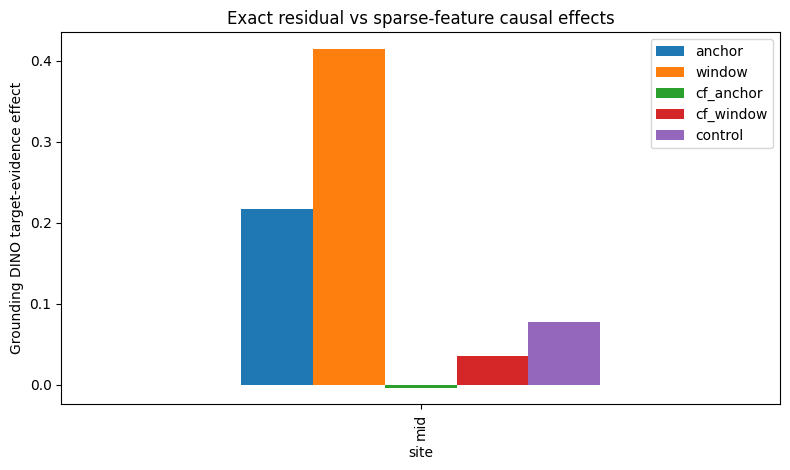

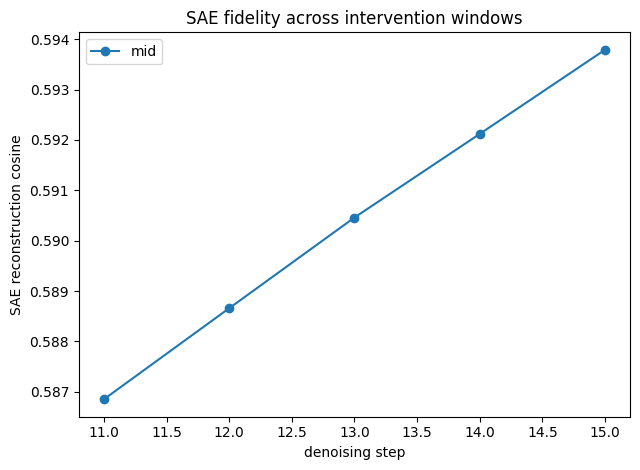

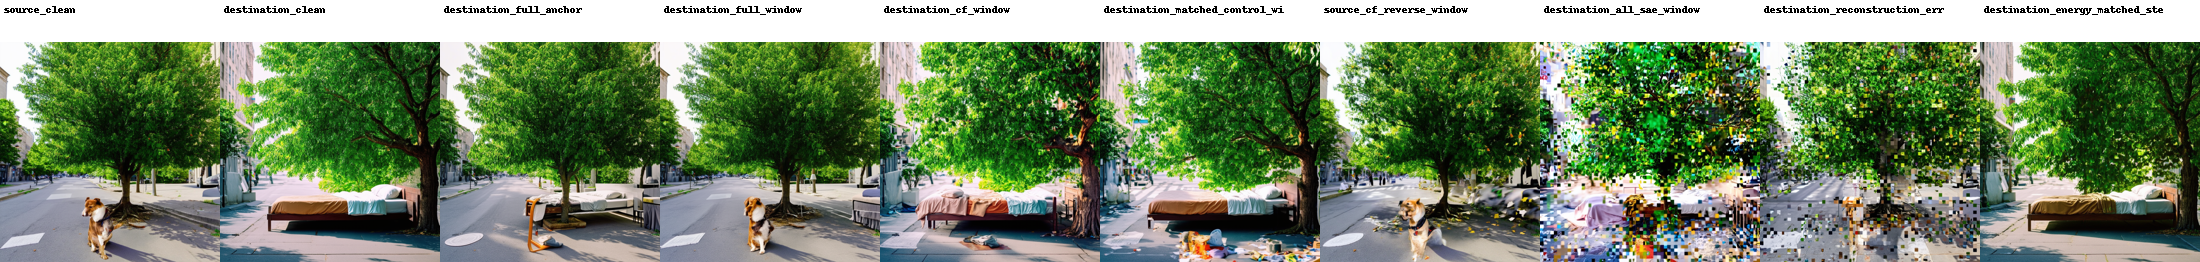

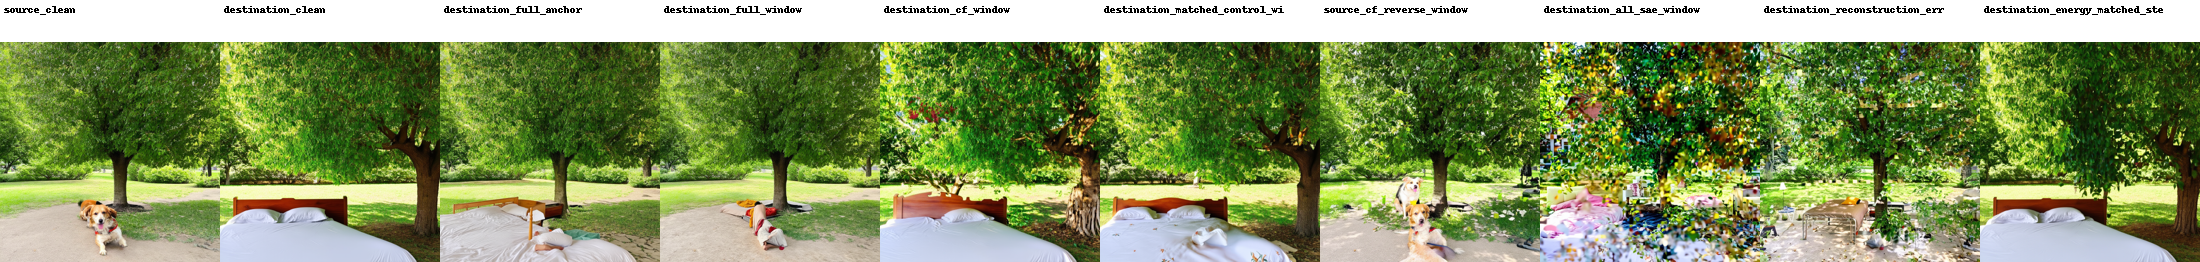

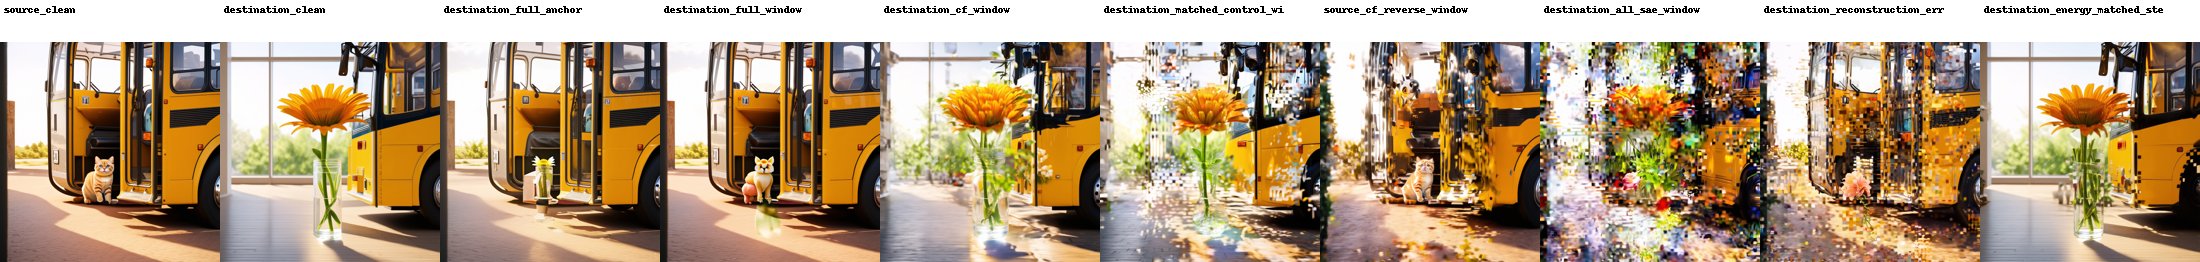

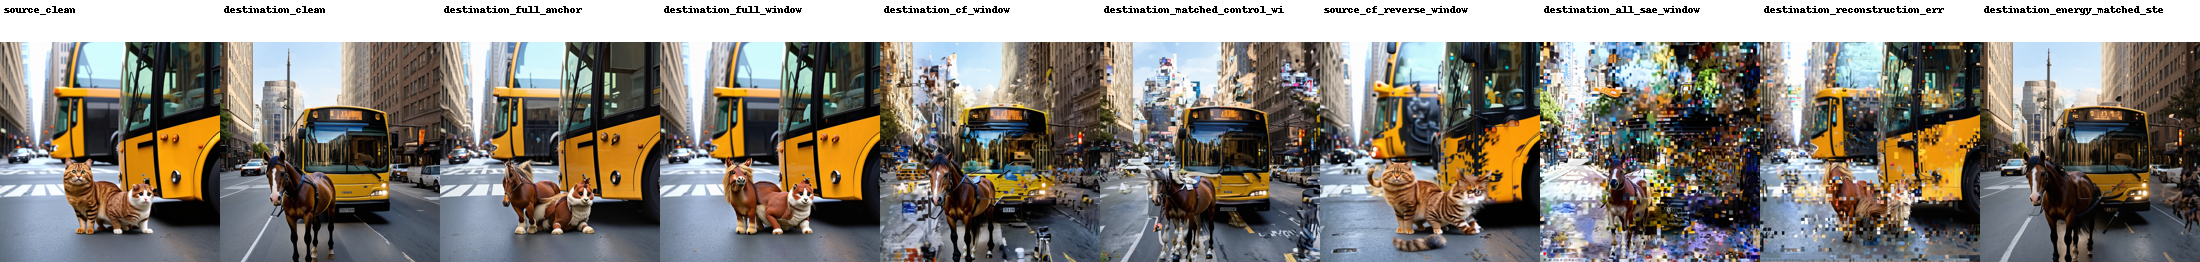

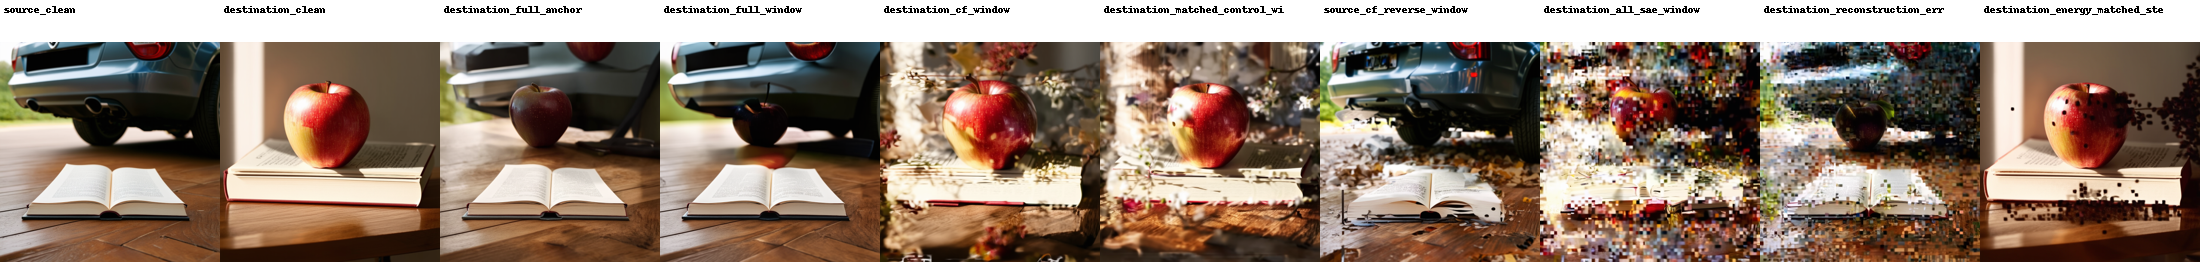

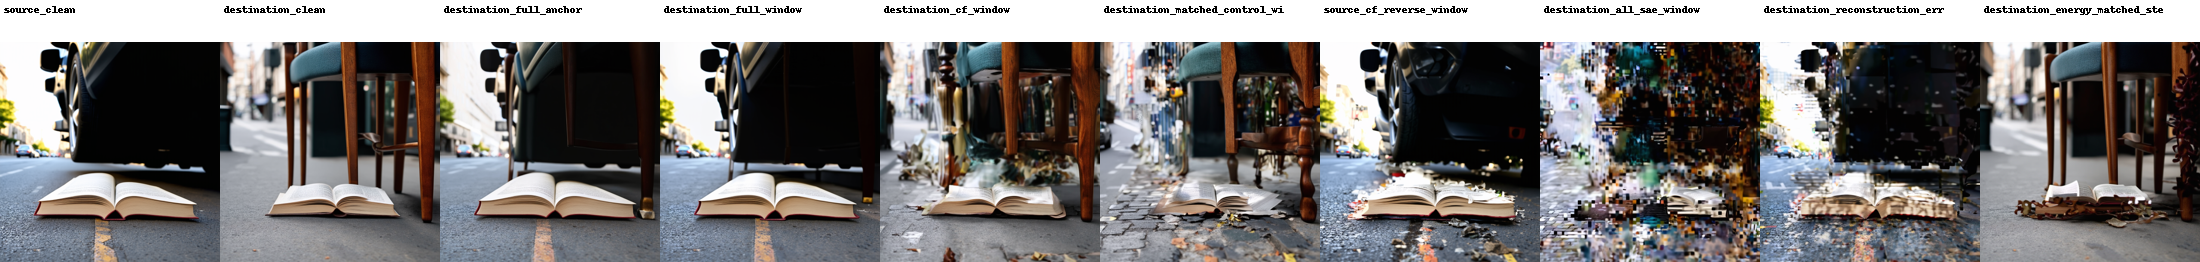

In [35]:
import matplotlib.pyplot as plt

fig,ax=plt.subplots(figsize=(8,4.8))
plot=primary_est.groupby("site",as_index=False).agg(anchor=("full_anchor_effect","mean"),window=("full_window_effect","mean"),cf_anchor=("cf_anchor_effect","mean"),cf_window=("cf_window_effect","mean"),control=("control_effect","mean"))
plot.set_index("site")[["anchor","window","cf_anchor","cf_window","control"]].plot(kind="bar",ax=ax)
ax.set_ylabel("Grounding DINO target-evidence effect")
ax.set_title("Exact residual vs sparse-feature causal effects")
fig.tight_layout(); fig.savefig(OUT_DIR/"figures"/"phase_a_effects.png",dpi=180); plt.show()

fig,ax=plt.subplots(figsize=(6.5,4.8))
for site,sub in recon_df.groupby("site"):
    g=sub.groupby("step")["cosine"].mean(); ax.plot(g.index,g.values,marker="o",label=site)
ax.set_xlabel("denoising step"); ax.set_ylabel("SAE reconstruction cosine"); ax.set_title("SAE fidelity across intervention windows"); ax.legend(); fig.tight_layout(); fig.savefig(OUT_DIR/"figures"/"sae_window_reconstruction.png",dpi=180); plt.show()

from PIL import ImageDraw

def thumb(path,size=(220,220)):
    im=Image.open(path).convert("RGB"); im.thumbnail(size); c=Image.new("RGB",size,"white"); c.paste(im,((size[0]-im.width)//2,(size[1]-im.height)//2)); return c

def causal_gallery(pair,site):
    arms=["source_clean","destination_clean","destination_full_anchor","destination_full_window","destination_cf_window","destination_matched_control_window","source_cf_reverse_window"]
    if site in passing_sites: arms += ["destination_all_sae_window","destination_reconstruction_error_window","destination_energy_matched_steer_window"]
    images=[]; titles=[]
    for arm in arms:
        if arm=="source_clean": p=clean_image_path(pair["pair_id"],"source",clean_seed)
        elif arm=="destination_clean": p=clean_image_path(pair["pair_id"],"destination",clean_seed)
        else:
            phase="phase_b" if arm in phase_b_arms else "phase_a"; p=OUT_DIR/phase/site/pair["pair_id"]/f"{arm}.png"
        if p.exists(): images.append(thumb(p)); titles.append(arm)
    w,h=220,220; th=42; canvas=Image.new("RGB",(len(images)*w,h+th),"white"); draw=ImageDraw.Draw(canvas)
    for i,(im,title) in enumerate(zip(images,titles)):
        draw.text((i*w+4,4),title[:30],fill=(0,0,0)); canvas.paste(im,(i*w,th))
    return canvas

for pair in active_test_pairs[:6]:
    for site in RUN_SITES:
        g=causal_gallery(pair,site); path=OUT_DIR/"galleries"/f"{safe_name(pair['pair_id'])}_{site}.png"; g.save(path)
        display(g)


## 19. 


## 20. Confirmatory stage

## 21. Artifact inventory


In [36]:
expected=[
    "split_manifest.csv","clean_capture_manifest.csv","sae_window_reconstruction_diagnostics.csv",
    "feature_discovery.csv","selected_features.csv","selected_features.json","control_matching.csv",
    "phase_a_manifest.csv","phase_a_scores.csv","phase_a_estimands.csv","site_gates.csv","primary_tests.csv",
    "phase_b_manifest.csv","phase_b_scores.csv","final_scores.csv","final_estimands.csv","decision_table_v2.csv",
]
inv=[]
for name in expected:
    p=OUT_DIR/name; inv.append({"artifact":name,"exists":p.exists(),"size_mib":p.stat().st_size/1024**2 if p.exists() else np.nan})
display(pd.DataFrame(inv))
print("Output directory:",OUT_DIR)


,artifact,exists,size_mib
0,split_manifest.csv,True,0.015333
1,clean_capture_manifest.csv,True,0.003896
2,sae_window_reconstruction_diagnostics.csv,True,0.038951
3,feature_discovery.csv,True,2.320368
4,selected_features.csv,True,0.022806
5,selected_features.json,True,0.003171
6,control_matching.csv,True,0.009586
7,phase_a_manifest.csv,True,0.056121
8,phase_a_scores.csv,True,0.087810
9,phase_a_estimands.csv,True,0.012209


Output directory: /home/jupyter/project/diffusion_attention_analysis_2/outputs/sd3_medium_sae_circuit_150/06_causal_mediation_v2
